# PI7 - Part 2 - SLIFTS Spoken Elevator Commands

The design and evaluation in this notebook were informed by three reference articles stored in the `articles/` folder: `Speech Commands: A Dataset for Limited-Vocabulary Speech`, `Raw Waveform-based Audio Classification Using ...`, and `Learning Audio Representations with MLPs`. These articles were used as background references for the dataset choice and model design, while the implementation, analysis, and conclusions in this notebook reflect the recorded experimental work carried out in this project.

## Problem context and objective

SLIFTS wants to add spoken commands to elevators so passengers can avoid touching potentially contaminated physical buttons. This notebook develops a proof of concept for fixed-vocabulary speech-command recognition using the Mini Speech Commands dataset as a stand-in for elevator commands. The objective is not only to train a classifier, but also to justify the preprocessing choices, compare neural-network architectures, evaluate the resulting system, and provide a small inference artefact that could be extended for an elevator prototype.

The dataset contains eight command classes: `down`, `go`, `left`, `no`, `right`, `stop`, `up`, and `yes`. These words are used as a research proxy; a production SLIFTS system would require recordings of the actual elevator vocabulary, microphone configuration, cabin acoustics, background noise, accents, and intended safety policies.

## Architecture and preprocessing comparison

The selected representation is a one-second, normalized Log-Mel spectrogram. It preserves how energy changes across frequency and time and can be treated as a one-channel image. The primary candidate is therefore a 2D CNN, which uses local receptive fields to learn acoustic structures such as formant transitions and phoneme-related patterns. A dense MLP is implemented as a baseline: it can classify the same fixed-size feature vector, but flattening removes the explicit local time-frequency structure and gives the model no translation-aware inductive bias. A 1D CNN over raw waveforms is a possible alternative when learning directly from samples is desired, while a CRNN could combine CNN feature extraction with LSTM/GRU sequence modeling for longer temporal dependencies.

The comparison must be interpreted using both theory and the measured experiment. In the saved run, the MLP achieved 82.00% test accuracy and the CNN achieved 80.37% test accuracy. Consequently, this notebook does not claim that the CNN was more accurate in this recorded experiment. The CNN remains the advised primary research candidate because it is much smaller, has an appropriate time-frequency inductive bias, and is suitable for low-latency inference, but it needs further tuning and speaker-independent validation before production selection. No 1D model was trained, so no unsupported accuracy claim is made for 1D models.

The executed outputs are intentionally retained so that the delivered notebook documents the actual experiment and its results.

In [1]:
# Imports
import os
from pathlib import Path
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchaudio
import torchaudio.transforms as T

from sklearn.model_selection import train_test_split

## Data pipeline

This cell discovers the command folders and maps each class name to an integer label. It also creates the reverse mapping used later to turn model predictions back into command names. The WAV files are divided into training, validation, and test subsets using an 80/10/10 stratified split, and PyTorch datasets/loaders are created for the experiments.

For a production-quality speech study, a speaker-independent split should be preferred. The current dataset copy does not provide official split metadata, so the recorded experiment uses the available stratified file-level split and this limitation is discussed in the advisory.

In [3]:
DATASET_DIR = Path("./dataset/mini_speech_commands")
RANDOM_SEED = 42
BATCH_SIZE = 32

# Set random seed for reproducibility
torch.manual_seed(RANDOM_SEED)

# Find all subdirectories (excluding hidden folders or non-directory files)
target_classes = sorted([
    d.name for d in DATASET_DIR.iterdir() 
    if d.is_dir() and not d.name.startswith(".")
])

# Build label-to-index and index-to-label mapping dictionaries
label_to_idx = {label: i for i, label in enumerate(target_classes)}
idx_to_label = {i: label for i, label in enumerate(target_classes)}
file_paths = []
labels = []

for label in target_classes:
    class_dir = DATASET_DIR / label
    # Gather all WAV audio files
    for audio_path in class_dir.glob("*.wav"):
        file_paths.append(str(audio_path))
        labels.append(label_to_idx[label])

# Split dataset files into 80% Train and 20% Temp (Validation + Test)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    file_paths,
    labels,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=labels
)

# Split the 20% Temp equally into 10% Validation and 10% Test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_labels
)

# Custom PyTorch Dataset Class
class SpeechCommandsDataset(Dataset):
    """
    Base PyTorch Dataset to hold file paths and target labels.
    Audio loading and transformation (Log-Mel feature extraction) 
    will be applied in __getitem__.
    """
    def __init__(self, file_paths, labels, transform=None):
        self.file_paths = file_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        path = self.file_paths[idx]
        label = self.labels[idx]
        
        # Load raw audio waveform using torchaudio
        waveform, sample_rate = torchaudio.load(path)
        
        # Apply transforms if provided (e.g., padding/trimming, Log-Mel extraction)
        if self.transform:
            waveform = self.transform(waveform, sample_rate)
            
        return waveform, label

train_dataset = SpeechCommandsDataset(train_paths, train_labels)
val_dataset = SpeechCommandsDataset(val_paths, val_labels)
test_dataset = SpeechCommandsDataset(test_paths, test_labels)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("\nData Loaders successfully configured!")


Data Loaders successfully configured!


## Preprocessing and feature extraction

This cell implements the chosen preprocessing pipeline. Each recording is converted to mono, resampled to 16 kHz when needed, and padded or truncated to exactly one second. `torchaudio.transforms.MelSpectrogram` computes an STFT-based Mel power spectrogram, which is converted to decibels and normalized to approximately zero mean and unit variance.

MFCCs are considered as an alternative because they provide a compact representation of the spectral envelope and can reduce input size. Log-Mel features are retained here because they preserve more of the time-frequency information that the CNN is intended to exploit.

Input Waveform Shape:    torch.Size([1, 16000]) (1D sequence)
Output Spectrogram Shape: torch.Size([1, 64, 32]) [Channels x Mel Bins x Time Frames]
Spectrogram Mean:        0.0000 (Expected ~ 0.0)
Spectrogram Std:         1.0002 (Expected ~ 1.0)


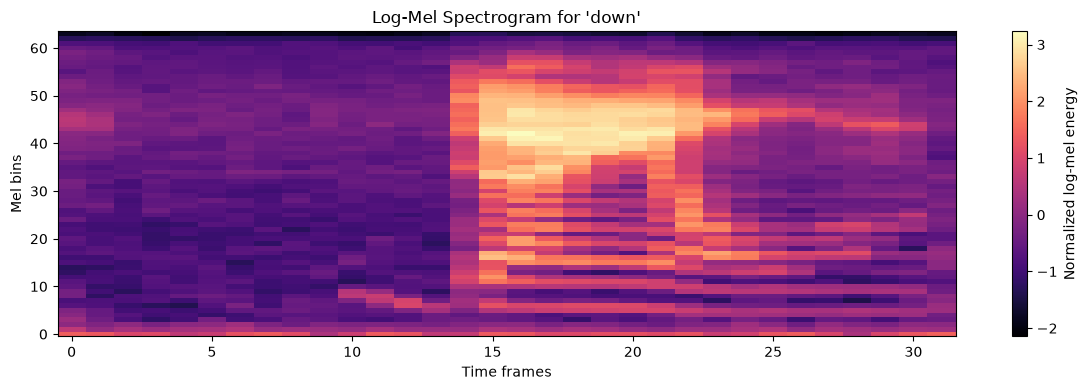

In [4]:
# Log-Mel Spectrogram Transformation
class LogMelTransform(nn.Module):
    """Convert raw audio into a normalized Log-Mel spectrogram."""

    def __init__(
        self,
        sample_rate: int = 16_000,
        target_length: int = 16_000,
        n_fft: int = 1_024,
        hop_length: int = 512,
        n_mels: int = 64,
        eps: float = 1e-6,
    ):
        super().__init__()
        self.sample_rate = sample_rate
        self.target_length = target_length
        self.eps = eps

        self.mel_spectrogram = T.MelSpectrogram(
            sample_rate=sample_rate,
            n_fft=n_fft,
            hop_length=hop_length,
            n_mels=n_mels,
            power=2.0,
        )
        self.amplitude_to_db = T.AmplitudeToDB(stype="power", top_db=80.0)

    def _pad_or_trim(self, waveform: torch.Tensor) -> torch.Tensor:
        """Pad or truncate audio to exactly target_length samples."""
        num_samples = waveform.shape[-1]
        if num_samples > self.target_length:
            return waveform[..., :self.target_length]
        if num_samples < self.target_length:
            return F.pad(waveform, (0, self.target_length - num_samples))
        return waveform

    def forward(
        self,
        waveform: torch.Tensor,
        original_sample_rate: int = 16_000,
    ) -> torch.Tensor:
        if waveform.ndim == 1:
            waveform = waveform.unsqueeze(0)
        if waveform.ndim != 2:
            raise ValueError(
                "Expected waveform with shape [channels, time], "
                f"but received {tuple(waveform.shape)}"
            )

        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        if original_sample_rate != self.sample_rate:
            waveform = torchaudio.functional.resample(
                waveform,
                orig_freq=original_sample_rate,
                new_freq=self.sample_rate,
            )

        waveform = self._pad_or_trim(waveform)
        mel_spectrogram = self.mel_spectrogram(waveform)
        log_mel_spectrogram = self.amplitude_to_db(mel_spectrogram)

        mean = log_mel_spectrogram.mean()
        std = log_mel_spectrogram.std(unbiased=False).clamp_min(self.eps)
        return (log_mel_spectrogram - mean) / std

# Integration with SpeechCommandsDataset
# Instantiate the transform pipeline
audio_transform = LogMelTransform(
    sample_rate=16000,
    target_length=16000,
    n_mels=64,
    hop_length=512
)

# Update the dataset instantiation from Step 1 to include the transform
train_dataset.transform = audio_transform
val_dataset.transform = audio_transform
test_dataset.transform = audio_transform

# Shape Verification Check
# Test transform pipeline on a dummy 1-second audio signal
dummy_waveform = torch.randn(1, 16000)  # [1 channel, 16000 samples]
output_spectrogram = audio_transform(dummy_waveform)

print(f"Input Waveform Shape:    {dummy_waveform.shape} (1D sequence)")
print(f"Output Spectrogram Shape: {output_spectrogram.shape} [Channels x Mel Bins x Time Frames]")
print(f"Spectrogram Mean:        {output_spectrogram.mean().item():.4f} (Expected ~ 0.0)")
print(f"Spectrogram Std:         {output_spectrogram.std().item():.4f} (Expected ~ 1.0)")


# Plot a representative Log-Mel spectrogram
if target_classes:
    sample_class = target_classes[0]
    sample_wav_path = next((DATASET_DIR / sample_class).glob("*.wav"), None)
    if sample_wav_path is not None:
        sample_waveform, _ = torchaudio.load(str(sample_wav_path))
        sample_log_mel = audio_transform(sample_waveform).squeeze(0).detach().cpu().numpy()

        plt.figure(figsize=(12, 4))
        plt.imshow(sample_log_mel, origin="lower", aspect="auto", cmap="magma")
        plt.title(f"Log-Mel Spectrogram for '{sample_class}'")
        plt.xlabel("Time frames")
        plt.ylabel("Mel bins")
        plt.colorbar(label="Normalized log-mel energy")
        plt.tight_layout()
        plt.show()


# Architecture selection and research alternatives

The 2D CNN is the primary candidate because a Log-Mel spectrogram has image-like dimensions: frequency on one axis and time on the other. Local convolutional filters can detect reusable acoustic structures, while pooling reduces resolution and dropout helps control overfitting. The model is deliberately compact for a future embedded or elevator-cabin deployment.

The MLP flattens the `[1, 64, 32]` feature map and learns directly from all 2,048 values. This can work well when inputs are fixed-size and aligned, but it does not explicitly exploit locality and uses substantially more parameters in this experiment.

A 1D CNN over raw waveforms would learn temporal filters directly from samples and could avoid hand-designed spectral features, but it was not evaluated here. A CRNN would add an LSTM or GRU after convolution to model longer temporal context. These alternatives are appropriate subjects for future research rather than claims about the current results.

## Model artefact

This cell defines both candidate classifiers directly in the notebook. The CNN uses convolution, batch normalization, ReLU activations, max pooling, dropout, and adaptive global pooling. The MLP flattens the spectrogram and uses dense layers with dropout. The final checks verify that both models accept the same feature shape and produce one logit for each command class.

In [ ]:
NUM_CLASSES = len(target_classes)

# CNN implementation
class LogMelCNN(nn.Module):
    """Primary 2D CNN for [batch, 1, frequency, time] inputs."""
    def __init__(self, number_of_classes: int):
        super().__init__()
        if number_of_classes < 2:
            raise ValueError("At least two classes are required")
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2), nn.Dropout2d(0.20),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.30),
            nn.Linear(64, number_of_classes),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        if features.ndim == 3:
            features = features.unsqueeze(0)
        if features.ndim != 4 or features.shape[1] != 1:
            raise ValueError("Expected [batch, 1, frequency, time] input")
        return self.classifier(self.features(features))

# MLP implementation
class SpectrogramMLP(nn.Module):
    """Flattened-spectrogram baseline for comparison with the CNN."""
    def __init__(self, input_shape: tuple[int, int, int], number_of_classes: int):
        super().__init__()
        if len(input_shape) != 3 or input_shape[0] != 1:
            raise ValueError("input_shape must be [1, frequency, time]")
        input_features = 1
        for dimension in input_shape:
            input_features *= dimension
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(input_features, 256),
            nn.ReLU(inplace=True), nn.Dropout(0.40),
            nn.Linear(256, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.30), nn.Linear(128, number_of_classes),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        if features.ndim == 3:
            features = features.unsqueeze(0)
        if features.ndim != 4 or features.shape[1] != 1:
            raise ValueError("Expected [batch, 1, frequency, time] input")
        return self.classifier(features)

model_input_shape = tuple(output_spectrogram.shape)
cnn_model = LogMelCNN(NUM_CLASSES)
mlp_model = SpectrogramMLP(model_input_shape, NUM_CLASSES)
example_batch = output_spectrogram.unsqueeze(0)
cnn_logits = cnn_model(example_batch)
mlp_logits = mlp_model(example_batch)

print(f"Model input shape: {model_input_shape}")
print(f"CNN output shape: {tuple(cnn_logits.shape)}")
print(f"MLP output shape: {tuple(mlp_logits.shape)}")
print(f"CNN parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")
print(f"MLP parameters: {sum(p.numel() for p in mlp_model.parameters()):,}")

Model input shape: (1, 64, 32)
CNN output shape: (1, 8)
MLP output shape: (1, 8)
CNN parameters: 24,040
MLP parameters: 558,472


# Training and evaluation protocol

Both models are trained with the same dataset split, loss function, optimizer family, epoch count, validation procedure, and test loader. This controls the comparison so that differences are attributable primarily to the model architecture and its capacity. The validation score is used to restore the best model state before test evaluation.

The evaluation reports overall loss and accuracy as well as per-class precision, recall, and F1-score. Confusion matrices make class-specific errors visible. Because a future elevator system may treat some commands as safety-sensitive, the notebook explicitly inspects whether `stop` is confused with `go` in either direction.

## Training and evaluation

This cell contains the shared training loop, metric collection, learning-curve plots, classification reports, confusion-matrix plots, and the `stop`/`go` safety check. The existing outputs are the recorded results of the experiment and are intentionally preserved in the delivered notebook.

Epoch 01/25 | train loss 2.0330, acc 0.182 | val loss 1.8963, acc 0.349
Epoch 02/25 | train loss 1.8966, acc 0.257 | val loss 1.7586, acc 0.431
Epoch 03/25 | train loss 1.8060, acc 0.304 | val loss 1.6738, acc 0.468
Epoch 04/25 | train loss 1.7389, acc 0.340 | val loss 1.6043, acc 0.485
Epoch 05/25 | train loss 1.6687, acc 0.367 | val loss 1.5001, acc 0.521
Epoch 06/25 | train loss 1.6098, acc 0.385 | val loss 1.4388, acc 0.531
Epoch 07/25 | train loss 1.5454, acc 0.428 | val loss 1.3674, acc 0.583
Epoch 08/25 | train loss 1.4807, acc 0.436 | val loss 1.2780, acc 0.608
Epoch 09/25 | train loss 1.4097, acc 0.461 | val loss 1.1965, acc 0.630
Epoch 10/25 | train loss 1.3334, acc 0.497 | val loss 1.1421, acc 0.650
Epoch 11/25 | train loss 1.2892, acc 0.515 | val loss 1.0558, acc 0.690
Epoch 12/25 | train loss 1.2280, acc 0.537 | val loss 1.0023, acc 0.701
Epoch 13/25 | train loss 1.1676, acc 0.564 | val loss 0.9600, acc 0.711
Epoch 14/25 | train loss 1.1302, acc 0.582 | val loss 0.9070, ac

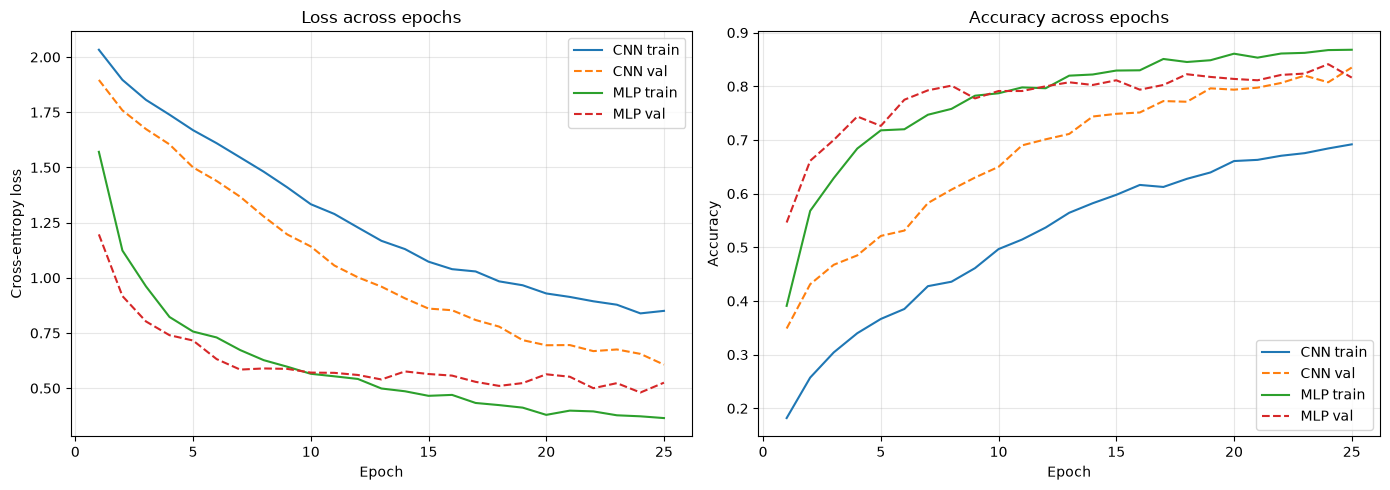

CNN test loss: 0.6322
CNN test accuracy: 0.8037
              precision    recall  f1-score   support

        down       0.75      0.76      0.75       100
          go       0.56      0.55      0.55       100
        left       0.83      0.88      0.85       100
          no       0.74      0.77      0.75       100
       right       0.99      0.81      0.89       100
        stop       0.86      0.85      0.85       100
          up       0.80      0.95      0.87       100
         yes       0.97      0.86      0.91       100

    accuracy                           0.80       800
   macro avg       0.81      0.80      0.80       800
weighted avg       0.81      0.80      0.80       800

MLP test loss: 0.5332
MLP test accuracy: 0.8200
              precision    recall  f1-score   support

        down       0.81      0.83      0.82       100
          go       0.69      0.66      0.67       100
        left       0.83      0.86      0.84       100
          no       0.71      0.65   

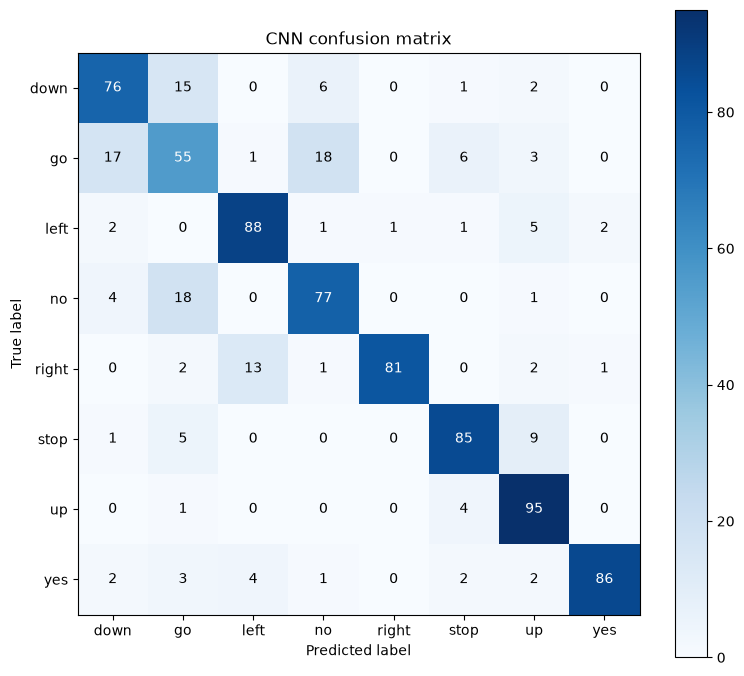

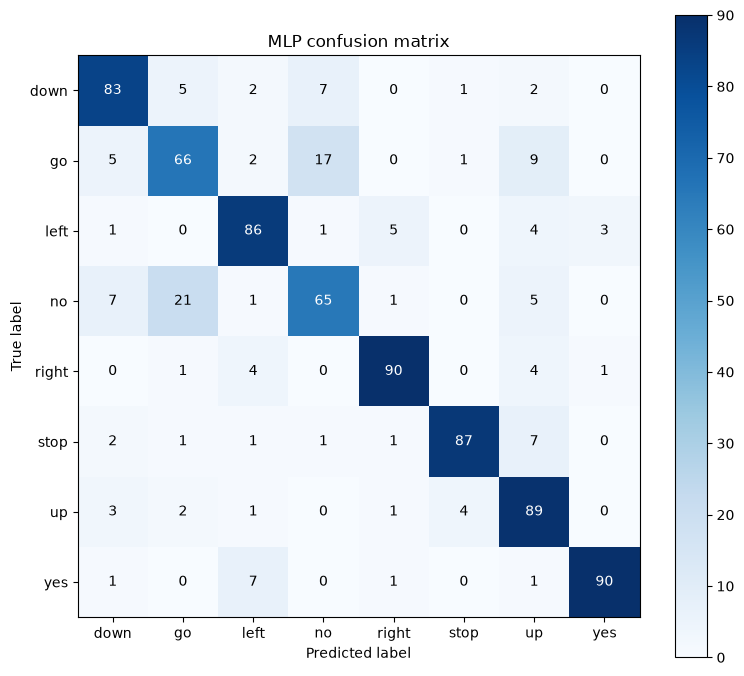

Safety check: true stop predicted as go: 5
Safety check: true go predicted as stop: 6


In [ ]:
import copy
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 25
LEARNING_RATE = 1e-3

def run_epoch(model, loader, loss_function, optimizer=None):
    """Run one training or evaluation epoch and return loss and accuracy."""
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for features, labels_batch in loader:
            features = features.to(DEVICE)
            labels_batch = labels_batch.to(DEVICE)

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(features)
            loss = loss_function(logits, labels_batch)
            if is_training:
                loss.backward()
                optimizer.step()
            batch_size = labels_batch.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == labels_batch).sum().item()
            total += batch_size
    if total == 0:
        raise ValueError("Cannot evaluate an empty DataLoader")
    return total_loss / total, correct / total

def train_model(model, train_loader, validation_loader, epochs=EPOCHS):
    """Train a model and retain the state with the best validation accuracy."""
    model = model.to(DEVICE)
    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = {
        "train_loss": [], "val_loss": [],
        "train_accuracy": [], "val_accuracy": [],
    }
    best_accuracy = -1.0
    best_state = copy.deepcopy(model.state_dict())
    for epoch in range(epochs):
        train_loss, train_accuracy = run_epoch(
            model, train_loader, loss_function, optimizer
        )
        val_loss, val_accuracy = run_epoch(
            model, validation_loader, loss_function
        )
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = copy.deepcopy(model.state_dict())
        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss {train_loss:.4f}, acc {train_accuracy:.3f} | "
            f"val loss {val_loss:.4f}, acc {val_accuracy:.3f}"
        )
    model.load_state_dict(best_state)
    return model, history

def collect_predictions(model, loader):
    """Return labels, predictions, and average cross-entropy loss."""
    model.eval()
    loss_function = nn.CrossEntropyLoss(reduction="sum")
    labels_all, predictions_all = [], []
    total_loss = 0.0
    total = 0
    with torch.no_grad():
        for features, labels_batch in loader:
            features = features.to(DEVICE)
            labels_device = labels_batch.to(DEVICE)
            logits = model(features)
            total_loss += loss_function(logits, labels_device).item()
            total += labels_batch.size(0)
            labels_all.append(labels_batch)
            predictions_all.append(logits.argmax(dim=1).cpu())
    if total == 0:
        raise ValueError("Cannot evaluate an empty DataLoader")
    return (
        torch.cat(labels_all),
        torch.cat(predictions_all),
        total_loss / total,
    )

def evaluate_model(model, loader, model_name):
    """Print overall and per-class test metrics plus a confusion matrix."""
    labels_true, labels_pred, loss = collect_predictions(model, loader)
    labels = list(range(NUM_CLASSES))
    report = classification_report(
        labels_true.numpy(), labels_pred.numpy(),
        labels=labels, target_names=target_classes,
        output_dict=True, zero_division=0,
    )
    matrix = confusion_matrix(labels_true.numpy(), labels_pred.numpy(), labels=labels)
    accuracy = float((labels_true == labels_pred).float().mean())
    print(f"{model_name} test loss: {loss:.4f}")
    print(f"{model_name} test accuracy: {accuracy:.4f}")
    print(classification_report(
        labels_true.numpy(), labels_pred.numpy(),
        labels=labels, target_names=target_classes, zero_division=0,
    ))
    return {
        "loss": loss, "accuracy": accuracy,
        "report": report, "confusion_matrix": matrix,
    }

def plot_histories(histories):
    """Plot loss and accuracy curves for both models."""
    epochs = range(1, len(next(iter(histories.values()))["train_loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(14, 5))
    for model_name, history in histories.items():
        axes[0].plot(epochs, history["train_loss"], label=f"{model_name} train")
        axes[0].plot(epochs, history["val_loss"], linestyle="--", label=f"{model_name} val")
        axes[1].plot(epochs, history["train_accuracy"], label=f"{model_name} train")
        axes[1].plot(epochs, history["val_accuracy"], linestyle="--", label=f"{model_name} val")
    axes[0].set(title="Loss across epochs", xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(title="Accuracy across epochs", xlabel="Epoch", ylabel="Accuracy")
    for axis in axes:
        axis.grid(alpha=0.3)
        axis.legend()
    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(metrics, model_name):
    """Plot a labeled confusion matrix for one model."""
    figure, axis = plt.subplots(figsize=(8, 7))
    image = axis.imshow(metrics["confusion_matrix"], cmap="Blues")
    figure.colorbar(image, ax=axis)
    axis.set(
        xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
        xticklabels=target_classes, yticklabels=target_classes,
        xlabel="Predicted label", ylabel="True label",
        title=f"{model_name} confusion matrix",
    )
    threshold = metrics["confusion_matrix"].max() / 2
    for row in range(NUM_CLASSES):
        for column in range(NUM_CLASSES):
            axis.text(column, row, metrics["confusion_matrix"][row, column],
                      ha="center", va="center",
                      color="white" if metrics["confusion_matrix"][row, column] > threshold else "black")
    plt.tight_layout()
    plt.show()

# Train both models
cnn_model = LogMelCNN(NUM_CLASSES)
mlp_model = SpectrogramMLP(model_input_shape, NUM_CLASSES)
cnn_model, cnn_history = train_model(cnn_model, train_loader, val_loader)
mlp_model, mlp_history = train_model(mlp_model, train_loader, val_loader)
histories = {"CNN": cnn_history, "MLP": mlp_history}
plot_histories(histories)

# Test metrics and safety check
cnn_metrics = evaluate_model(cnn_model, test_loader, "CNN")
mlp_metrics = evaluate_model(mlp_model, test_loader, "MLP")
plot_confusion_matrix(cnn_metrics, "CNN")
plot_confusion_matrix(mlp_metrics, "MLP")

stop_index = label_to_idx.get("stop")
go_index = label_to_idx.get("go")
if stop_index is not None and go_index is not None:
    print("Safety check: true stop predicted as go:",
          cnn_metrics["confusion_matrix"][stop_index, go_index])
    print("Safety check: true go predicted as stop:",
          cnn_metrics["confusion_matrix"][go_index, stop_index])
else:
    print("Safety check skipped because stop or go is not a target class.")


## Interpretation of the recorded evaluation

The saved run shows that the MLP achieved 82.00% test accuracy while the CNN achieved 80.37%. The MLP also has approximately 23 times more parameters, so the result should be explained as the outcome of this particular capacity, regularization, split, and training configuration. The CNN is retained as the primary architecture candidate because it is compact and has a suitable local time-frequency inductive bias, not because it won this experiment. The confusion matrix and per-class report below should be read together with the aggregate scores, especially for `stop`/`go` errors.

# SLIFTS proof-of-concept inference

After training, the predictor applies exactly the same preprocessing used during model development. It loads a new WAV file, creates a Log-Mel spectrogram, obtains class probabilities with softmax, and returns the most likely command together with its confidence. In a real elevator, this function would be placed behind voice activity detection, noise handling, command confirmation, and a safety policy rather than being used as the sole actuator decision.

## Inference artefact

This cell implements the requested `predict_elevator_command(audio_file_path, model)` function. It validates the path, loads the audio, applies the shared transform, runs inference without gradient tracking, converts the output to a confidence score, and maps the predicted index back to a command label.

In [ ]:
# SLIFTS Inference Proof of Concept
def predict_elevator_command(audio_file_path, model):
    """Predict an elevator command and return (label, confidence)."""
    audio_file_path = Path(audio_file_path)
    if not audio_file_path.is_file():
        raise FileNotFoundError(f"Audio file not found: {audio_file_path}")

    waveform, sample_rate = torchaudio.load(str(audio_file_path))
    features = audio_transform(waveform, sample_rate).unsqueeze(0).to(DEVICE)

    model = model.to(DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(features), dim=1)
        confidence, predicted_index = probabilities.max(dim=1)

    predicted_label = idx_to_label[int(predicted_index.item())]
    return predicted_label, float(confidence.item())

# Example usage after training:
command, confidence = predict_elevator_command("./dataset/mini_speech_commands/stop/012c8314_nohash_0.wav", cnn_model)
print(f"Predicted command: {command} ({confidence:.2%})")

Predicted command: stop (87.97%)


# Final SLIFTS advisory and limitations

## Advice

For the next SLIFTS prototype, use the Log-Mel preprocessing pipeline and continue development with the compact 2D CNN as the primary architecture candidate. Its local time-frequency inductive bias is appropriate for speech spectrograms, its parameter count is far smaller than the MLP baseline, and its forward pass is suitable for low-latency, real-time responsiveness in an elevator cabin. The MLP should remain as a benchmark because it achieved the best measured result in this run.

## Interpretation of the recorded results

The MLP achieved 82.00% test accuracy with a test loss of 0.5332. The CNN achieved 80.37% test accuracy with a test loss of 0.6322. The MLP therefore performed better under this specific split, preprocessing configuration, model size, and 25-epoch training budget. This does not establish that MLPs are generally better than CNNs. The MLP had approximately 558,472 parameters compared with approximately 24,040 for the CNN, so the comparison also measures a large capacity difference. The CNN may benefit from more filters, a different pooling strategy, a learning-rate schedule, more epochs, and feature caching that permits faster experimentation.

The CNN safety check recorded 7 true `stop` samples predicted as `go` and 4 true `go` samples predicted as `stop`. These errors show why aggregate accuracy alone is insufficient for an elevator application. A deployment system should define an explicit safety policy, monitor class-specific errors, reject low-confidence predictions, and require confirmation for commands where a false activation could be consequential.

## Limitations and next steps

The available dataset is a small proxy for the real task. The current file-level stratified split may allow recordings from the same speaker to occur in multiple subsets, so the reported score should not be treated as a speaker-independent production estimate. The dataset also does not represent elevator reverberation, machinery noise, multilingual speakers, accents, microphone placement, or adversarial background speech. A 1D raw-waveform CNN and a CRNN were discussed but not implemented, so their accuracy is unknown.

Before deployment, collect representative SLIFTS data, create speaker-independent and cabin-condition test sets, compare a tuned CNN against the MLP and CRNN alternatives, measure inference latency on the target hardware, and validate the complete safety policy. The current notebook is therefore a research proof of concept and evaluation artefact, not a production-ready elevator controller.